In [1]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

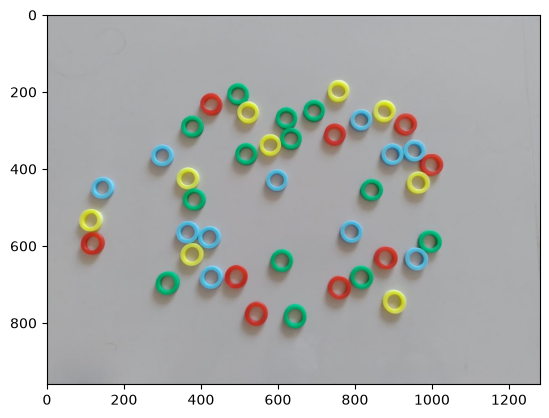

In [2]:
filepath = "../img/1.jpg"
img = cv.imread(filepath)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
imghsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
# hue vai nos ajudar mais do que rgb!
imgray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
plt.imshow(img)
imgray = cv.GaussianBlur(imgray, (7, 7), 1.5)

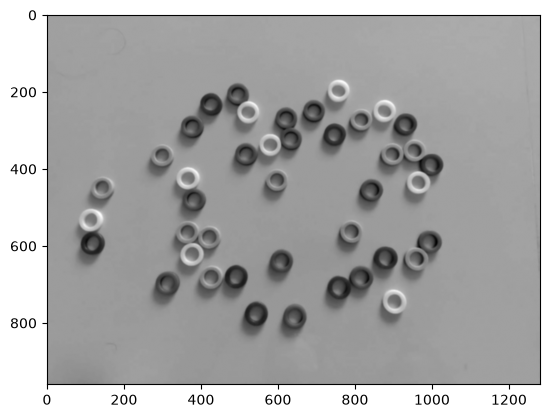

In [3]:
plt.imshow(imgray, cmap='gray')

In [4]:
circulos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=10, maxRadius=40)
circulosinternos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT,20, 20, param1=50, param2=50, minRadius=15, maxRadius=25)


In [5]:
circulos = np.uint16(np.around(circulos))
print(circulos.shape)
# circulosinternos = np.uint16(np.around(circulosinternos))
# print(circulosinternos.shape)

imgfinal = img

# imgfinalinternos = img.copy()

for i in circulos[0, :]:
    cv.circle(imgfinal, (i[0], i[1]), i[2], (0, 255, 0), 1)

    cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), (0, 255, 0), 1)

    cv.circle(imgfinal, (i[0],i[1]), 2, (0, 0, 255), 3)

# for i in circulosinternos[0, :]:
#     cv.circle(imgfinalinternos, (i[0], i[1]), i[2], (0, 255, 0), 1)

#     cv.circle(imgfinalinternos, (i[0],i[1]), 2, (0, 0, 255), 3)

(1, 42, 3)


In [6]:
# print(circulos)

In [7]:
# print(circulosinternos)

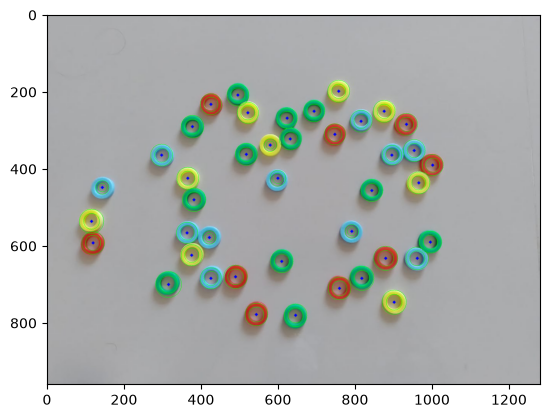

In [8]:
plt.imshow(imgfinal)

In [9]:
# plt.imshow(imgfinalinternos)

ok entao temos os centros, os raios possivelmente errados e a imagem em hsv

no entanto! temos que a proporcao entre o raio interno e externo eh constante

posso pegar a moda de todos os pixels? vai ser O(t*40^2)